# 03 Validação e baselines

Como meço o AUC, o que o mede mal, e a que modelos simples tenho de ganhar. Daqui para a frente todos os números vêm do mesmo esquema e das mesmas funções (`utils.py` e `cv.py`) que o `train.py` vai usar.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

sys.path.insert(0, "../task1/best_model")        # as funções que o train.py e o predict também usam
sys.path.insert(0, "../task1/training_code")
import utils, cv

AZUL, VERM = "#0072B2", "#D55E00"          # paleta Okabe-Ito, legível por daltónicos
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "normal", "axes.titlelocation": "left",
    "figure.figsize": (3.4, 2.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.unicode_minus": False, "savefig.dpi": 200,
    "savefig.bbox": "tight", "legend.frameon": False,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def guardar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

In [2]:
raw = pd.read_csv("../data/classification_task1_train.csv", parse_dates=["Date"])
comp = raw[(raw["Year"] < 2020) & raw["CHL"].notna()].copy()      # 2013-2019, só linhas completas; 2020 fica de fora
SPEC = utils.DEFAULT_SPEC
print(f"{len(comp)} linhas completas, {comp['HAB'].sum()} eventos HAB, anos {comp['Year'].min()} a {comp['Year'].max()}")

476 linhas completas, 62 eventos HAB, anos 2013 a 2019


## 1. Como valido

O test set são anos futuros (2021 a 2023) e linhas da mesma data parecem-se. Por isso a validation tem de deixar anos inteiros de fora, e nunca linhas ao acaso. Uso leave-one-year-out cross-validation em 2013-2019: em cada fold, um ano inteiro é o validation set e os outros seis são o training set. As escolhas de hiperparâmetros e de modelo (notebook 04) usam uma nested cross-validation: dentro de cada fold exterior, um leave-one-year-out interior nos seis anos de training.

In [3]:
por_ano = comp.groupby("Year").agg(linhas=("HAB", "size"), eventos=("HAB", "sum"))
por_ano["dá AUC"] = por_ano["eventos"] > 0
por_ano

,linhas,eventos,dá AUC
Year,,,
2013,60,8,True
2014,32,0,False
2015,25,10,True
2016,81,14,True
2017,102,0,False
2018,87,13,True
2019,89,17,True


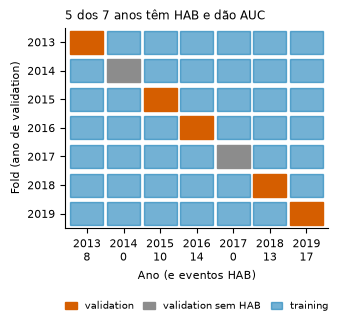

In [4]:
anos = list(por_ano.index)
fig, ax = plt.subplots()
for i, val in enumerate(anos):
    for j, ano in enumerate(anos):
        cor = ("#8C8C8C" if por_ano.loc[val, "eventos"] == 0 else VERM) if ano == val else AZUL      # cinzento: validation sem HAB
        ax.add_patch(plt.Rectangle((j - 0.45, i - 0.4), 0.9, 0.8, color=cor, alpha=1 if ano == val else 0.55))
ax.set(xlim=(-0.6, len(anos) - 0.4), ylim=(len(anos) - 0.5, -0.5), xticks=range(len(anos)), yticks=range(len(anos)),
       xlabel="Ano (e eventos HAB)", ylabel="Fold (ano de validation)", title=f"{int(por_ano['dá AUC'].sum())} dos {len(anos)} anos têm HAB e dão AUC")
ax.set_xticklabels([f"{a}\n{int(e)}" for a, e in por_ano["eventos"].items()]); ax.set_yticklabels(anos); ax.grid(False)
ax.legend(handles=[Patch(color=VERM, label="validation"), Patch(color="#8C8C8C", label="validation sem HAB"), Patch(color=AZUL, alpha=0.55, label="training")],
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=7, columnspacing=1.0, handlelength=1.2)
guardar(fig, "11_esquema_cv")

Dos 7 anos, 5 têm HAB nas linhas completas, com entre 8 e 17 eventos cada. O 2014 e o 2017 têm zero eventos, por isso não dão AUC como validation year. Continuam a servir de training nos outros folds, e as suas previsões entram no AUC agrupado, onde contam como negativos.

Reporto sempre dois números. O AUC médio por ano é a média dos 5 AUC. O AUC agrupado junta as previsões fora-do-fold das 476 linhas e calcula um só AUC. O professor provavelmente avalia 2021-2023 de uma vez, e o agrupado também mede se os scores de anos diferentes são comparáveis entre si.

In [5]:
def logreg(spec):
    return lambda tr, va: utils.score(utils.fit_logreg(tr, spec), va)

def extra_trees(tr, va):
    return utils.score_extra_trees(utils.fit_extra_trees(tr, n_estimators=1000), va)          # com 300 árvores a semente muda o AUC em 0.016

def resumo(fit_score, nome):
    """AUC de cada ano, a média por ano e o AUC agrupado (todas as previsões fora-do-fold juntas)."""
    auc, oof = cv.loyo(comp, fit_score)
    return {"nome": nome, **{int(y): v for y, v in auc.dropna().items()}, "média por ano": auc.mean(), "agrupado": cv.pooled_auc(comp, oof)}

pd.DataFrame([resumo(logreg(SPEC), "Logistic Regression"), resumo(extra_trees, "Extra Trees")]).set_index("nome").round(3)

,2013,2015,2016,2018,2019,média por ano,agrupado
nome,,,,,,,
Logistic Regression,0.673,0.773,0.858,0.898,0.784,0.797,0.796
Extra Trees,0.707,0.767,0.817,0.906,0.793,0.798,0.773


A Logistic Regression dá 0.797 por ano e 0.796 agrupado. O Extra Trees dá 0.798 e 0.773. Os dois empatam por ano, e a logística ganha 0.023 no agrupado, o que sugere que os scores do Extra Trees são menos comparáveis entre anos. Tenho de ter isto em conta quando comparar modelos.

## 2. Porque não um k-fold aleatório

O que acontece se parto as linhas ao acaso em vez de por ano? Repito 20 vezes um 5-fold estratificado com sementes diferentes.

In [6]:
def kfold_aleatorio(fit_score, sementes=20):
    medias, agrupados = [], []
    for s in range(sementes):
        oof, aucs = pd.Series(np.nan, index=comp.index), []
        for i_tr, i_va in StratifiedKFold(5, shuffle=True, random_state=s).split(comp, comp["HAB"]):
            va = comp.iloc[i_va]
            oof.loc[va.index] = fit_score(comp.iloc[i_tr], va)
            aucs.append(roc_auc_score(va["HAB"], oof.loc[va.index]))
        medias.append(np.mean(aucs)); agrupados.append(roc_auc_score(comp["HAB"], oof))
    return np.mean(medias), np.mean(agrupados)

aleatorio = {nome: kfold_aleatorio(f) for nome, f in [("Logistic Regression", logreg(SPEC)), ("Extra Trees", extra_trees)]}
pd.DataFrame(aleatorio, index=["média por fold", "agrupado"]).T.round(3)

,média por fold,agrupado
Logistic Regression,0.811,0.807
Extra Trees,0.818,0.813


In [7]:
dias = comp["Date"].map(pd.Timestamp.toordinal).to_numpy()

def com_treino_perto(i_val, i_train, margem=7):
    """Para cada linha de validation: há no training uma linha a menos de 7 dias?"""
    return [np.abs(dias[i_train] - dias[i]).min() <= margem for i in i_val]

i_tr, i_va = next(iter(StratifiedKFold(5, shuffle=True, random_state=0).split(comp, comp["HAB"])))
perto_loyo = sum((com_treino_perto(np.where(comp["Year"] == y)[0], np.where(comp["Year"] != y)[0]) for y in anos), [])
print(f"k-fold aleatório: {np.mean(com_treino_perto(i_va, i_tr)):.1%} das linhas de validation têm training a menos de 7 dias")
print(f"leave-one-year-out: {np.mean(perto_loyo):.1%}")

k-fold aleatório: 90.6% das linhas de validation têm training a menos de 7 dias
leave-one-year-out: 0.8%


O AUC sobe de 0.797 para 0.811 na Logistic Regression e de 0.798 para 0.818 no Extra Trees. É um ganho pequeno, mas o mecanismo está lá: com folds aleatórios, 90.6% das linhas de validation têm no training uma linha a menos de 7 dias, contra 0.8% no leave-one-year-out. Aqui o efeito é pequeno e não tenho como garantir que seja assim com outro modelo ou outras features.

Decisão: não uso folds aleatórios para escolher nem comparar modelos. Esta célula fica só como aviso.

## 3. Walk-forward, a verificação mais dura

E se o modelo nunca vir o futuro? Cada ano é previsto só com os anos anteriores. O 2013 não tem passado, e o 2014 e o 2017 não dão AUC.

In [8]:
def resumo_walk_forward(fit_score, nome):
    auc, oof = cv.walk_forward(comp, fit_score)
    visto = oof.notna()
    return {"nome": nome, **{int(y): v for y, v in auc.dropna().items()}, "média por ano": auc.mean(),
            "agrupado": roc_auc_score(comp.loc[visto, "HAB"], oof[visto])}

pd.DataFrame([resumo_walk_forward(logreg(SPEC), "Logistic Regression"), resumo_walk_forward(extra_trees, "Extra Trees")]).set_index("nome").round(3)

,2015,2016,2018,2019,média por ano,agrupado
nome,,,,,,
Logistic Regression,0.58,0.609,0.927,0.784,0.725,0.752
Extra Trees,0.74,0.611,0.911,0.793,0.764,0.741


É bem mais duro: a Logistic Regression dá 0.725 por ano e 0.752 agrupado, e o Extra Trees 0.764 e 0.741. Os primeiros folds treinam com poucos dados: o 2015 treina só com 2013 e 2014 (8 eventos) e o 2016 com 18, e é aí que o AUC cai (0.580 e 0.609 na logística). Já o 2018 chega a 0.927. Como o modelo final treina com todos os anos, o walk-forward subestima o que espero.

Decisão: o leave-one-year-out é o esquema principal, e o walk-forward fica como verificação secundária. Uma conclusão em que confio tem de sobreviver também aqui.

## 4. Baselines

A que tenho de ganhar, e o que acrescenta cada ingrediente? Quatro degraus, cada um a justificar o seguinte, mais um que acrescentei entre a sazonalidade e a logística completa (sazonalidade + cluster).

In [9]:
def com(**mudancas):
    return {**SPEC, **mudancas}

def constante(tr, va):
    return np.zeros(len(va))

BASELINES = {"constante": constante,
             "só sazonalidade": logreg(com(SST=False, UI=False, CHL=None, unc=None, cluster=None)),
             "só ambientais": logreg(com(season=[], cluster=None)),
             "sazonalidade + cluster": logreg(com(SST=False, UI=False, CHL=None, unc=None)),
             "logística completa": logreg(SPEC)}
base = pd.DataFrame([resumo(f, nome) for nome, f in BASELINES.items()]).set_index("nome")
base.round(3)

,2013,2015,2016,2018,2019,média por ano,agrupado
nome,,,,,,,
constante,0.500,0.500,0.500,0.500,0.500,0.500,0.500
só sazonalidade,0.512,0.637,0.776,0.848,0.704,0.695,0.709
só ambientais,0.502,0.787,0.601,0.769,0.554,0.643,0.609
sazonalidade + cluster,0.649,0.693,0.821,0.899,0.825,0.778,0.804
logística completa,0.673,0.773,0.858,0.898,0.784,0.797,0.796


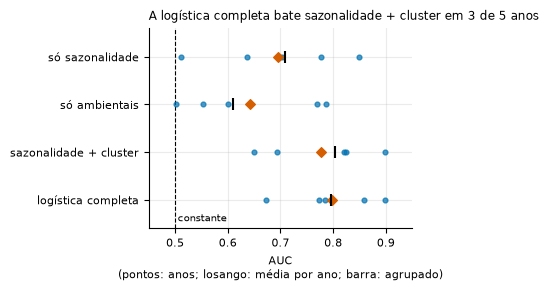

In [10]:
anos_col = [c for c in base.columns if isinstance(c, int)]
sem_const = base.drop(index="constante")
vitorias = int((base.loc["logística completa", anos_col] > base.loc["sazonalidade + cluster", anos_col]).sum())
fig, ax = plt.subplots()
for i, (nome, linha) in enumerate(sem_const.iterrows()):
    ax.scatter(linha[anos_col].astype(float), [i] * len(anos_col), color=AZUL, s=12, alpha=0.7, zorder=3)
    ax.scatter(linha["média por ano"], i, color=VERM, marker="D", s=24, zorder=4)
    ax.scatter(linha["agrupado"], i, color="k", marker="|", s=70, zorder=4)
ax.axvline(0.5, color="k", lw=0.8, ls="--"); ax.text(0.505, len(sem_const) - 0.55, "constante", fontsize=7)
ax.set(yticks=range(len(sem_const)), yticklabels=sem_const.index, xlim=(0.45, 0.95), ylim=(len(sem_const) - 0.4, -0.6),
       xlabel="AUC\n(pontos: anos; losango: média por ano; barra: agrupado)",
       title=f"A logística completa bate sazonalidade + cluster em {vitorias} de {len(anos_col)} anos")
guardar(fig, "12_baselines")

O preditor constante dá AUC 0.5: o melhor constante é a classe mais comum e não ordena nada. Qualquer modelo tem de o bater com clareza. A sazonalidade sozinha dá 0.695 por ano e 0.709 agrupado, bem acima de 0.5, por isso há sinal mesmo sem variáveis ambientais. As variáveis ambientais sozinhas dão só 0.643 e 0.609: sem a época e o cluster valem pouco. Sazonalidade e cluster juntos dão 0.778 e 0.804, e a logística completa 0.797 e 0.796.

O que as variáveis ambientais acrescentam à sazonalidade e ao cluster é pouco: +0.019 na média por ano e -0.008 no agrupado. Melhoram 2013, 2015 e 2016, o 2018 fica igual (0.898 contra 0.899) e piora 2019 (-0.041). No notebook 02 já se via que a SST e a UI não contavam, e que o CHL era o que mais pesava depois da época e do cluster.

Decisão: a baseline a bater é sazonalidade + cluster (0.778 e 0.804), não a constante. Um modelo mais complexo só se justifica se a ganhar com clareza.

In [11]:
ref = json.load(open("reference_numbers.json"))["LOYO_2013_2019"]
for nome, fit_score, chave in [("Extra Trees da referência (300 árvores)", lambda tr, va: utils.score_extra_trees(utils.fit_extra_trees(tr), va), "ET"), ("Logistic Regression com log na incerteza", logreg(dict(SPEC, unc="log")), "LR")]:
    auc, _ = cv.loyo(comp, fit_score)
    print(f"{nome}: {auc.dropna().round(3).tolist()} média {auc.mean():.3f} | referência {ref[chave]['por_ano']} média {ref[chave]['media']}")

Extra Trees da referência (300 árvores): [0.721, 0.78, 0.817, 0.914, 0.792] média 0.805 | referência [0.721, 0.78, 0.817, 0.914, 0.792] média 0.805
Logistic Regression com log na incerteza: [0.661, 0.773, 0.86, 0.903, 0.786] média 0.797 | referência [0.661, 0.773, 0.86, 0.903, 0.786] média 0.797


O Extra Trees da referência (300 árvores, semente 0) reproduz-se exatamente (0.805). Esse valor era a semente mais favorável: com 1000 árvores, que é o que uso daqui para a frente, dá 0.798. A logística com o log na incerteza também reproduz a referência (0.797). Com a incerteza em bruto, que é o `SPEC` deste notebook, a média por ano continua a ser 0.797 e o único ano que se afasta da referência é 2013 (0.673 contra 0.661), como já assinalei no notebook 02.